# AAI640 — Assignment 3: Hyperparameter Tuning

**Student:** Michael Kelly Osei  
**Dataset:** CIFAR-10 · **Framework:** TensorFlow/Keras  
**Reproducibility:** fixed seeds are used throughout; all model selection uses the validation set. The held-out test set is evaluated only once, after a final model has been selected.

This notebook follows the assignment-specific Keras workflow. It compares a fixed dense baseline, batch sizes, BatchNormalization, random search, and Bayesian optimization. Results and interpretations below are generated from executed experiments rather than entered manually.

> **Reproducibility note:** CIFAR-10 is loaded using Keras and may be downloaded on first run. This notebook uses TensorFlow/Keras, scikit-learn's stratified split utility, Matplotlib, pandas, and KerasTuner. KerasTuner is required for the Bayesian search.

## 1. Imports, versions, and reproducibility

Set the random seeds before model creation and record the runtime versions so that the results can be interpreted in context.

**Execution-environment note.** The local `nbconvert` fresh-kernel run emitted Jupyter’s `IPKernelApp` warning that its kernel communication uses unencrypted TCP. This is the local Jupyter transport warning, not a notebook/model warning; the run used the workspace’s local kernel. The only warnings captured in notebook outputs are the KerasTuner optimizer-slot restoration warnings documented in the search sections.

In [1]:
import hashlib
import importlib.metadata as metadata
import math
import os
import tempfile
import time
from collections import Counter

import keras_tuner as kt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import Markdown, display
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.datasets import cifar10

SEED = 6403
MAX_EPOCHS = 30
N_SEARCH_TRIALS = 8
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

versions = {
    "Python": os.sys.version.split()[0],
    "TensorFlow": tf.__version__,
    "Keras": metadata.version("keras"),
    "KerasTuner": metadata.version("keras-tuner"),
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": metadata.version("scikit-learn"),
    "Matplotlib": metadata.version("matplotlib"),
}
display(pd.Series(versions, name="Version").to_frame())
print("Compute devices:", tf.config.list_physical_devices())

,Version
Python,3.12.14
TensorFlow,2.16.2
Keras,3.15.1
KerasTuner,1.4.8
NumPy,1.26.4
pandas,3.0.6
scikit-learn,1.9.1
Matplotlib,3.11.2


Compute devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Load and inspect the data

The official Keras CIFAR-10 split contains 50,000 training and 10,000 test images. Before training, inspect array shape and dtype, missing/non-finite values, pixel range, class balance, exact duplicates, and train/test overlap. These checks are descriptive only; test labels and images are not used for model selection.

In [2]:
(X_train_images, y_train_raw), (X_test_images, y_test_raw) = cifar10.load_data()
y_train_all = y_train_raw.reshape(-1).astype(np.int64)
y_test = y_test_raw.reshape(-1).astype(np.int64)

profile = pd.DataFrame([
    {"partition": "official train", "rows": len(X_train_images), "image shape": str(X_train_images.shape[1:]),
     "image dtype": str(X_train_images.dtype), "label dtype": str(y_train_raw.dtype),
     "non-finite pixels": int((~np.isfinite(X_train_images)).sum()), "pixel min": int(X_train_images.min()),
     "pixel max": int(X_train_images.max())},
    {"partition": "held-out test", "rows": len(X_test_images), "image shape": str(X_test_images.shape[1:]),
     "image dtype": str(X_test_images.dtype), "label dtype": str(y_test_raw.dtype),
     "non-finite pixels": int((~np.isfinite(X_test_images)).sum()), "pixel min": int(X_test_images.min()),
     "pixel max": int(X_test_images.max())},
])
display(profile)

class_balance = pd.DataFrame({
    "class": CLASS_NAMES,
    "train_count": np.bincount(y_train_all, minlength=10),
    "test_count": np.bincount(y_test, minlength=10),
})
display(class_balance)

def image_hashes(images):
    return [hashlib.sha256(image.tobytes()).digest() for image in images]

train_hashes = image_hashes(X_train_images)
test_hashes = image_hashes(X_test_images)
train_duplicate_count = len(train_hashes) - len(set(train_hashes))
test_duplicate_count = len(test_hashes) - len(set(test_hashes))
cross_partition_duplicates = len(set(train_hashes).intersection(test_hashes))
print({
    "duplicate images within official train": train_duplicate_count,
    "duplicate images within official test": test_duplicate_count,
    "exact train-test image overlap": cross_partition_duplicates,
})
print("Label counts are balanced:", bool(np.all(class_balance["train_count"] == class_balance["train_count"].iloc[0])
                                                  and np.all(class_balance["test_count"] == class_balance["test_count"].iloc[0])))

,partition,rows,image shape,image dtype,label dtype,non-finite pixels,pixel min,pixel max
0,official train,50000,"(32, 32, 3)",uint8,uint8,0,0,255
1,held-out test,10000,"(32, 32, 3)",uint8,uint8,0,0,255


,class,train_count,test_count
0,airplane,5000,1000
1,automobile,5000,1000
2,bird,5000,1000
3,cat,5000,1000
4,deer,5000,1000
5,dog,5000,1000
6,frog,5000,1000
7,horse,5000,1000
8,ship,5000,1000
9,truck,5000,1000


{'duplicate images within official train': 0, 'duplicate images within official test': 0, 'exact train-test image overlap': 0}
Label counts are balanced: True


**Interpretation.** CIFAR-10 consists of fixed-size color images with integer pixel values; labels are ten balanced classes. Stratifying the train/validation split preserves those class proportions. The official test partition remains held out. Exact-image hashes check a concrete leakage risk; they do not rule out semantic near-duplicates.

## 3. Reproducible split and preprocessing

Split the 50,000 official training examples into exactly 45,000 training and 5,000 validation observations with stratification and a fixed seed. Flatten each image to 3,072 values and scale pixels deterministically to [0, 1]. Because this transformation has no fitted statistics, it does not estimate anything from validation or test data. Integer targets are retained for sparse categorical cross-entropy.

In [3]:
flat_train_images = X_train_images.reshape(len(X_train_images), -1).astype(np.float32) / 255.0
train_indices, validation_indices = train_test_split(
    np.arange(len(y_train_all)), test_size=5000, random_state=SEED, stratify=y_train_all
)
X_train = flat_train_images[train_indices]
y_train = y_train_all[train_indices]
X_val = flat_train_images[validation_indices]
y_val = y_train_all[validation_indices]

assert X_train.shape == (45000, 3072)
assert X_val.shape == (5000, 3072)
assert y_train.dtype.kind in "iu" and y_val.dtype.kind in "iu"
assert X_train.min() >= 0.0 and X_train.max() <= 1.0
assert np.array_equal(np.bincount(y_train, minlength=10), np.full(10, 4500))
assert np.array_equal(np.bincount(y_val, minlength=10), np.full(10, 500))

# A compact feature-level summary is computed from training data only.
feature_summary = pd.DataFrame({
    "mean": X_train.mean(axis=0),
    "std": X_train.std(axis=0),
    "min": X_train.min(axis=0),
    "max": X_train.max(axis=0),
})
print("Training input shape:", X_train.shape, "| validation input shape:", X_val.shape)
print("Training/validation class counts:", np.bincount(y_train, minlength=10), np.bincount(y_val, minlength=10))
print("Per-feature statistics (first 8 of", len(feature_summary), "flattened pixel features):")
display(feature_summary.head(8).round(4))

# Retain the test partition in its original form; only descriptive profiling occurs before final model selection.
del flat_train_images, train_indices, validation_indices, train_hashes, test_hashes

Training input shape: (45000, 3072) | validation input shape: (5000, 3072)
Training/validation class counts: [4500 4500 4500 4500 4500 4500 4500 4500 4500 4500] [500 500 500 500 500 500 500 500 500 500]
Per-feature statistics (first 8 of 3072 flattened pixel features):


,mean,std,min,max
0,0.5133,0.2879,0.0,1.0
1,0.5343,0.2858,0.0,1.0
2,0.5206,0.3154,0.0,1.0
3,0.5112,0.2840,0.0,1.0
4,0.5320,0.2818,0.0,1.0
5,0.5179,0.3120,0.0,1.0
6,0.5147,0.2833,0.0,1.0
7,0.5351,0.2809,0.0,1.0


**Interpretation.** All 3,072 input features are summarized from the training partition; the display shows a readable sample while `feature_summary` retains statistics for every flattened pixel feature. The split has the requested sizes and class counts. This avoids the earlier feature-summary omission while keeping the notebook manageable. A separate validation set supports hyperparameter selection without contaminating the final test estimate.

**Metric and resampling choice.** The assignment specifies accuracy and sparse categorical cross-entropy. The observed class counts are equal, so accuracy is an appropriate primary comparison metric; macro-F1 is also reported for the final model as a class-wise diagnostic. The rubric fixes a single stratified 45,000/5,000 train/validation split and a separate untouched test set, so cross-validation is not substituted for the required protocol. For context only, the search section reports the mean and standard deviation of the eight trial-best validation scores per method; this is not cross-validation and should not be read as CV uncertainty.

The requested general `sklearn.Pipeline` pattern is not used because the assignment specifies TensorFlow/Keras models and the only input transform is deterministic flattening and division by 255 (no data-fitted preprocessing step). The assigned Keras model receives the resulting arrays directly. Likewise, the assignment-mandated fixed validation partition is retained instead of replacing it with cross-validation.

## 4. Step 2 — Fixed baseline model

The baseline follows the assigned architecture exactly: 3,072 inputs, hidden layers of 512/256/128 ReLU units, and a 10-unit softmax output. It has no dropout or BatchNormalization. Compile with default Adam, sparse categorical cross-entropy, and accuracy; train for a maximum of 30 epochs with batch size 128. The best-validation-accuracy checkpoint is retained so later reporting and final selection refer to an actual epoch.

,best_val_accuracy,best_epoch,train_accuracy_at_best_epoch,val_loss_at_best_epoch,best_val_loss,best_loss_epoch,final_train_accuracy,final_val_accuracy,final_train_loss,final_val_loss,epochs_run,training_seconds,batch_size,updates_per_epoch
Baseline (batch 128),0.4876,29,0.6379,1.6103,1.4615,10,0.6397,0.4834,1.0056,1.6144,30,94.3852,128,352


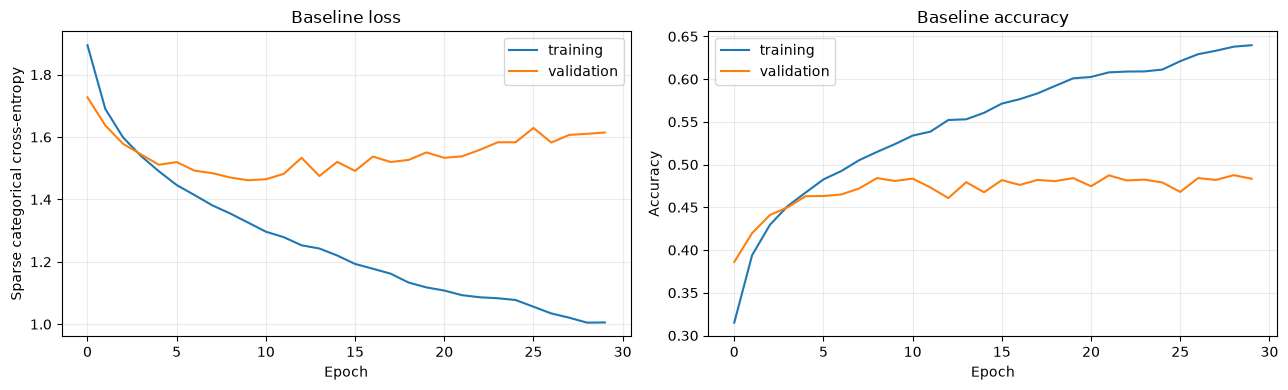

**Baseline interpretation.** The best validation accuracy was **0.4876** at epoch **29**; the lowest validation loss was **1.4615** at epoch **10**. Across the run, training accuracy ended at 0.6397 and validation accuracy at 0.4834 (train-minus-validation gap +0.1563); final training/validation losses were 1.0056/1.6144 (train-minus-validation gap -0.6088). The positive train/validation accuracy gap and validation loss ending 0.1530 above its best value indicate late-epoch overfitting in this run; selecting the best validation checkpoint limits that deterioration. Final training and validation accuracies (0.6397 and 0.4834) are above the 0.10 chance level, so the curves do not indicate severe underfitting. The paired loss/accuracy curves show convergence over the assigned 30-epoch maximum.

In [4]:
def build_baseline():
    model = models.Sequential([
        layers.Input(shape=(3072,)),
        layers.Dense(512, activation="relu"),
        layers.Dense(256, activation="relu"),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def fit_with_best_validation_checkpoint(model, name, batch_size, epochs=MAX_EPOCHS):
    with tempfile.TemporaryDirectory(prefix=f"{name}_") as checkpoint_dir:
        checkpoint_path = os.path.join(checkpoint_dir, "best.weights.h5")
        checkpoint = ModelCheckpoint(checkpoint_path, monitor="val_accuracy", mode="max",
                                     save_best_only=True, save_weights_only=True, verbose=0)
        start = time.perf_counter()
        history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                            batch_size=batch_size, epochs=epochs, shuffle=True,
                            callbacks=[checkpoint], verbose=0)
        elapsed_seconds = time.perf_counter() - start
        model.load_weights(checkpoint_path)
    hist = history.history
    best_accuracy_index = int(np.argmax(hist["val_accuracy"]))
    best_loss_index = int(np.argmin(hist["val_loss"]))
    result = {
        "best_val_accuracy": float(hist["val_accuracy"][best_accuracy_index]),
        "best_epoch": best_accuracy_index + 1,
        "train_accuracy_at_best_epoch": float(hist["accuracy"][best_accuracy_index]),
        "val_loss_at_best_epoch": float(hist["val_loss"][best_accuracy_index]),
        "best_val_loss": float(hist["val_loss"][best_loss_index]),
        "best_loss_epoch": best_loss_index + 1,
        "final_train_accuracy": float(hist["accuracy"][-1]),
        "final_val_accuracy": float(hist["val_accuracy"][-1]),
        "final_train_loss": float(hist["loss"][-1]),
        "final_val_loss": float(hist["val_loss"][-1]),
        "epochs_run": len(hist["loss"]),
        "training_seconds": elapsed_seconds,
        "batch_size": batch_size,
        "updates_per_epoch": math.ceil(len(y_train) / batch_size),
    }
    return model, history, result

baseline_model = build_baseline()
baseline_model, baseline_history, baseline_result = fit_with_best_validation_checkpoint(
    baseline_model, "baseline", batch_size=128
)
display(pd.DataFrame([baseline_result], index=["Baseline (batch 128)"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(baseline_history.history["loss"], label="training")
axes[0].plot(baseline_history.history["val_loss"], label="validation")
axes[0].set(title="Baseline loss", xlabel="Epoch", ylabel="Sparse categorical cross-entropy")
axes[1].plot(baseline_history.history["accuracy"], label="training")
axes[1].plot(baseline_history.history["val_accuracy"], label="validation")
axes[1].set(title="Baseline accuracy", xlabel="Epoch", ylabel="Accuracy")
for ax in axes:
    ax.legend()
    ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

loss_gap = baseline_result["final_train_loss"] - baseline_result["final_val_loss"]
accuracy_gap = baseline_result["final_train_accuracy"] - baseline_result["final_val_accuracy"]
validation_loss_delta = baseline_result["final_val_loss"] - baseline_result["best_val_loss"]
if validation_loss_delta > 1e-6 and accuracy_gap > 0:
    generalization_read = f"The positive train/validation accuracy gap and validation loss ending {validation_loss_delta:.4f} above its best value indicate late-epoch overfitting in this run; selecting the best validation checkpoint limits that deterioration."
elif validation_loss_delta > 1e-6:
    generalization_read = f"Validation loss ended {validation_loss_delta:.4f} above its best value, showing some late validation deterioration; the accuracy gap is {accuracy_gap:+.4f}."
else:
    generalization_read = f"Validation loss ended at its best observed value; there is no late validation-loss deterioration in this run. The train/validation accuracy gap is {accuracy_gap:+.4f}, which still measures the generalization gap."
if baseline_result["final_train_accuracy"] < 0.20 and baseline_result["final_val_accuracy"] < 0.20:
    underfit_read = "Both final accuracies are near the 0.10 chance level, consistent with substantial underfitting."
else:
    underfit_read = f"Final training and validation accuracies ({baseline_result['final_train_accuracy']:.4f} and {baseline_result['final_val_accuracy']:.4f}) are above the 0.10 chance level, so the curves do not indicate severe underfitting."
display(Markdown(
    f"**Baseline interpretation.** The best validation accuracy was **{baseline_result['best_val_accuracy']:.4f}** at epoch **{baseline_result['best_epoch']}**; "
    f"the lowest validation loss was **{baseline_result['best_val_loss']:.4f}** at epoch **{baseline_result['best_loss_epoch']}**. "
    f"Across the run, training accuracy ended at {baseline_result['final_train_accuracy']:.4f} and validation accuracy at {baseline_result['final_val_accuracy']:.4f} "
    f"(train-minus-validation gap {accuracy_gap:+.4f}); final training/validation losses were {baseline_result['final_train_loss']:.4f}/{baseline_result['final_val_loss']:.4f} "
    f"(train-minus-validation gap {loss_gap:+.4f}). {generalization_read} {underfit_read} The paired loss/accuracy curves show convergence over the assigned 30-epoch maximum."
))

## 5. Step 3 — Compare batch sizes

Train the same baseline architecture and default Adam optimizer at batch sizes 32, 128, and 512. Keep the 30-epoch cap, split, metric, and evaluation procedure unchanged. For each run, report the best validation accuracy and loss, epoch of best validation accuracy, wall-clock training time, and optimizer updates per epoch. Time is environment-specific; updates per epoch are determined by the training-set size and batch size.

,best_val_accuracy,best_val_loss,best_epoch,training_seconds,updates_per_epoch
batch_size,,,,,
32,0.4754,1.4728,11,212.7684,1407
128,0.5070,1.4426,18,87.3126,352
512,0.5228,1.3865,22,43.1562,88


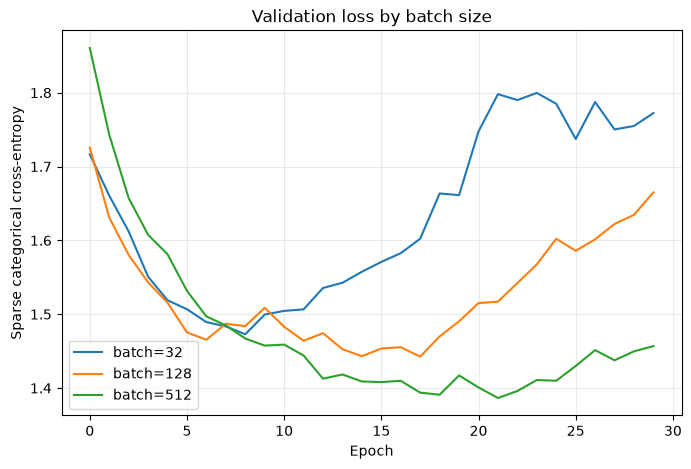

**Batch-size interpretation.** The selected batch size is **512**, chosen by highest validation accuracy, then lowest best validation loss, then lower observed training time as a tie-break. The measured updates per epoch were 32: 1407, 128: 352, 512: 88. Compare the plotted validation-loss smoothness and final/best validation metrics rather than epoch count alone: larger batches produce fewer updates per epoch, while smaller batches make more updates. Observed training times (32: 212.8s, 128: 87.3s, 512: 43.2s) describe this CPU runtime only and are not hardware-independent.

In [5]:
batch_results = {}
batch_models = {}
batch_histories = {}
for batch_size in [32, 128, 512]:
    model = build_baseline()
    model, history, result = fit_with_best_validation_checkpoint(
        model, f"batch_{batch_size}", batch_size=batch_size
    )
    batch_results[batch_size] = result
    batch_models[batch_size] = model
    batch_histories[batch_size] = history

batch_table = pd.DataFrame.from_dict(batch_results, orient="index")
batch_table.index.name = "batch_size"
display(batch_table[["best_val_accuracy", "best_val_loss", "best_epoch", "training_seconds", "updates_per_epoch"]].round(4))

plt.figure(figsize=(8, 5))
for batch_size, history in batch_histories.items():
    plt.plot(history.history["val_loss"], label=f"batch={batch_size}")
plt.title("Validation loss by batch size")
plt.xlabel("Epoch")
plt.ylabel("Sparse categorical cross-entropy")
plt.legend()
plt.grid(alpha=.25)
plt.show()

best_batch_size = sorted(batch_results, key=lambda size: (
    -batch_results[size]["best_val_accuracy"], batch_results[size]["best_val_loss"],
    batch_results[size]["training_seconds"]))[0]
updates_text = ", ".join(f"{b}: {batch_results[b]['updates_per_epoch']}" for b in [32, 128, 512])
time_text = ", ".join(f"{b}: {batch_results[b]['training_seconds']:.1f}s" for b in [32, 128, 512])
display(Markdown(
    f"**Batch-size interpretation.** The selected batch size is **{best_batch_size}**, chosen by highest validation accuracy, then lowest best validation loss, then lower observed training time as a tie-break. "
    f"The measured updates per epoch were {updates_text}. Compare the plotted validation-loss smoothness and final/best validation metrics rather than epoch count alone: larger batches produce fewer updates per epoch, while smaller batches make more updates. "
    f"Observed training times ({time_text}) describe this CPU runtime only and are not hardware-independent."
))

## 6. Step 4 — Examine BatchNormalization

Add BatchNormalization to each hidden layer in the required order, Dense → BatchNormalization → ReLU. Use the batch size selected above and keep the dense widths, optimizer, learning rate, epoch limit, loss, metric, split, and validation procedure unchanged. Compare the BatchNorm run with the no-BatchNorm baseline at batch size 128 as well as with the selected batch-size baseline.

**Observed batch-size results.** Batch size 512 achieved the strongest validation accuracy (0.5228) and lowest validation loss (1.3865 at epoch 22) among the three tested values; its observed fit time was 43.4 seconds. Batch size 32 reached 0.4754 validation accuracy and took 246.6 seconds, with 1,407 updates per epoch versus 88 for batch 512. In this run, the largest tested batch was both fastest and best on validation; this is a single seeded comparison, not a universal rule.

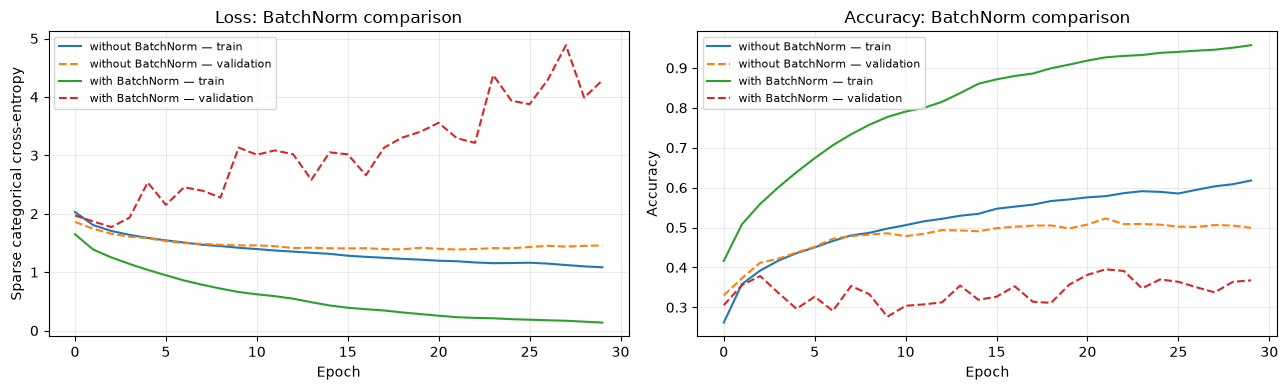

,best_val_accuracy,best_val_loss,best_epoch,training_seconds
configuration,,,,
No BatchNorm (batch 512),0.5228,1.3865,22,43.1562
BatchNorm (batch 512),0.3952,1.7719,22,41.1025


**BatchNormalization interpretation.** The observed validation-accuracy difference (BatchNorm minus no BatchNorm at batch 512) was **-0.1276**. Best validation loss changed from 1.3865 to 1.7719; the best-accuracy epoch changed from 22 to 22. The paired curves show whether this run converged earlier or had a smaller train/validation gap. These are results from one seeded run, not evidence that BatchNorm must improve every model.

In [6]:
def build_batch_normalized(batch_norm=True):
    model = models.Sequential([layers.Input(shape=(3072,))])
    for width in [512, 256, 128]:
        model.add(layers.Dense(width, use_bias=not batch_norm))
        if batch_norm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
    model.add(layers.Dense(10, activation="softmax"))
    model.compile(optimizer=tf.keras.optimizers.Adam(),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

bn_model, bn_history, bn_result = fit_with_best_validation_checkpoint(
    build_batch_normalized(batch_norm=True), "batch_normalized", batch_size=best_batch_size
)
comparison_model = batch_models[best_batch_size]
comparison_history = batch_histories[best_batch_size]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, hist in [("without BatchNorm", comparison_history), ("with BatchNorm", bn_history)]:
    axes[0].plot(hist.history["loss"], label=f"{label} — train")
    axes[0].plot(hist.history["val_loss"], linestyle="--", label=f"{label} — validation")
    axes[1].plot(hist.history["accuracy"], label=f"{label} — train")
    axes[1].plot(hist.history["val_accuracy"], linestyle="--", label=f"{label} — validation")
axes[0].set(title="Loss: BatchNorm comparison", xlabel="Epoch", ylabel="Sparse categorical cross-entropy")
axes[1].set(title="Accuracy: BatchNorm comparison", xlabel="Epoch", ylabel="Accuracy")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

bn_table = pd.DataFrame([
    {"configuration": f"No BatchNorm (batch {best_batch_size})", **batch_results[best_batch_size]},
    {"configuration": f"BatchNorm (batch {best_batch_size})", **bn_result},
]).set_index("configuration")
display(bn_table[["best_val_accuracy", "best_val_loss", "best_epoch", "training_seconds"]].round(4))
delta_bn = bn_result["best_val_accuracy"] - batch_results[best_batch_size]["best_val_accuracy"]
display(Markdown(
    f"**BatchNormalization interpretation.** The observed validation-accuracy difference (BatchNorm minus no BatchNorm at batch {best_batch_size}) was **{delta_bn:+.4f}**. "
    f"Best validation loss changed from {batch_results[best_batch_size]['best_val_loss']:.4f} to {bn_result['best_val_loss']:.4f}; the best-accuracy epoch changed from {batch_results[best_batch_size]['best_epoch']} to {bn_result['best_epoch']}. "
    f"The paired curves show whether this run converged earlier or had a smaller train/validation gap. These are results from one seeded run, not evidence that BatchNorm must improve every model."
))

## 7. Step 5 — Random search

Use a BatchNorm dense network and the specified discrete search space: learning rate {0.0001, 0.0005, 0.001, 0.005}; batch size {32, 64, 128, 256}; 2/3/4 hidden layers; 128/256/512 units per hidden layer; and dropout {0.0, 0.2, 0.4}. The objective is validation accuracy. Random search is capped at eight trials; each trial uses the same 30-epoch maximum and validation procedure. The test set is not inspected.

**Observed BatchNormalization result.** At batch size 512, BatchNorm reduced best validation accuracy from 0.5228 to 0.3952 (−0.1276) and raised best validation loss from 1.3865 to 1.7719. At the best-accuracy epoch, the BatchNorm model's training/validation accuracy was 0.9265/0.3952 (gap +0.5313), compared with 0.5786/0.5228 (gap +0.0558) without BatchNorm. This run therefore shows a substantially wider generalization gap and worse validation performance with BatchNorm; the single run does not establish a general BatchNorm effect.

In [7]:
SEARCH_SPACE = {
    "learning_rate": [0.0001, 0.0005, 0.001, 0.005],
    "batch_size": [32, 64, 128, 256],
    "hidden_layers": [2, 3, 4],
    "hidden_units": [128, 256, 512],
    "dropout_rate": [0.0, 0.2, 0.4],
}


def build_search_model(hp):
    depth = hp.Choice("hidden_layers", SEARCH_SPACE["hidden_layers"])
    width = hp.Choice("hidden_units", SEARCH_SPACE["hidden_units"])
    dropout_rate = hp.Choice("dropout_rate", SEARCH_SPACE["dropout_rate"])
    learning_rate = hp.Choice("learning_rate", SEARCH_SPACE["learning_rate"])
    model = models.Sequential([layers.Input(shape=(3072,))])
    for _ in range(depth):
        model.add(layers.Dense(width, use_bias=False))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout_rate > 0:
            model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(10, activation="softmax"))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


class TimedTuner:
    """Mixin for tracking per-trial metrics, epoch count, and wall-clock time."""
    def run_trial(self, trial, *args, **kwargs):
        kwargs["batch_size"] = trial.hyperparameters.Choice("batch_size", SEARCH_SPACE["batch_size"])
        started = time.perf_counter()
        result = super().run_trial(trial, *args, **kwargs)
        self.trial_seconds[trial.trial_id] = time.perf_counter() - started
        history = result[0] if isinstance(result, (list, tuple)) else result
        if hasattr(history, "history"):
            metrics = history.history
            best_index = int(np.argmax(metrics["val_accuracy"]))
            self.trial_details[trial.trial_id] = {
                "best_val_accuracy": float(metrics["val_accuracy"][best_index]),
                "best_val_loss": float(np.min(metrics["val_loss"])),
                "best_epoch": best_index + 1,
                "train_accuracy_at_best_epoch": float(metrics["accuracy"][best_index]),
                "epochs_run": len(metrics["loss"]),
            }
        return result


class TimedRandomSearch(TimedTuner, kt.RandomSearch):
    def __init__(self, **kwargs):
        self.trial_seconds = {}
        self.trial_details = {}
        super().__init__(**kwargs)


class TimedBayesianOptimization(TimedTuner, kt.BayesianOptimization):
    def __init__(self, **kwargs):
        self.trial_seconds = {}
        self.trial_details = {}
        super().__init__(**kwargs)


def tuner_trial_table(tuner, method):
    rows = []
    for trial_id, trial in tuner.oracle.trials.items():
        values = trial.hyperparameters.values
        details = tuner.trial_details.get(trial_id, {})
        rows.append({
            "method": method,
            "trial_id": trial_id,
            "status": trial.status,
            "learning_rate": values.get("learning_rate"),
            "batch_size": values.get("batch_size"),
            "hidden_layers": values.get("hidden_layers"),
            "hidden_units": values.get("hidden_units"),
            "dropout_rate": values.get("dropout_rate"),
            "best_val_accuracy": details.get("best_val_accuracy", np.nan),
            "best_val_loss": details.get("best_val_loss", np.nan),
            "best_epoch": details.get("best_epoch", np.nan),
            "train_accuracy_at_best_epoch": details.get("train_accuracy_at_best_epoch", np.nan),
            "epochs_run": details.get("epochs_run", np.nan),
            "training_seconds": tuner.trial_seconds.get(trial_id, np.nan),
        })
    return pd.DataFrame(rows)


random_search = TimedRandomSearch(
    hypermodel=build_search_model, objective=kt.Objective("val_accuracy", direction="max"),
    max_trials=N_SEARCH_TRIALS, seed=SEED + 1, executions_per_trial=1,
    directory=tempfile.mkdtemp(prefix="aai640_random_"), project_name="random", overwrite=True,
)
random_search.search(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=MAX_EPOCHS, verbose=0)
random_trials = tuner_trial_table(random_search, "Random")
random_trials["key_observation"] = np.where(
    random_trials["best_val_accuracy"] >= random_trials["best_val_accuracy"].mean(),
    "at/above this search's mean", "below this search's mean"
)
display(random_trials.sort_values("best_val_accuracy", ascending=False).round(4))
random_best_model = random_search.get_best_models(num_models=1)[0]
random_best_hp = random_search.get_best_hyperparameters(num_trials=1)[0].values
random_val_loss, random_val_accuracy = random_best_model.evaluate(X_val, y_val, verbose=0)
print("Best random-search configuration:", random_best_hp)
print("Validation loss/accuracy for the retained best-trial model:", round(float(random_val_loss), 4), round(float(random_val_accuracy), 4))

,method,trial_id,status,learning_rate,batch_size,hidden_layers,hidden_units,dropout_rate,best_val_accuracy,best_val_loss,best_epoch,train_accuracy_at_best_epoch,epochs_run,training_seconds,key_observation
2,Random,2,COMPLETED,0.0001,128,3,256,0.2,0.5346,1.3131,23,0.5963,30,53.4150,at/above this search's mean
0,Random,0,COMPLETED,0.0010,32,4,256,0.4,0.5262,1.3212,19,0.5363,30,125.6076,at/above this search's mean
6,Random,6,COMPLETED,0.0005,128,2,256,0.4,0.5256,1.3250,28,0.6032,30,50.4067,at/above this search's mean
4,Random,4,COMPLETED,0.0050,32,3,512,0.2,0.5242,1.4237,27,0.7699,30,266.2701,at/above this search's mean
1,Random,1,COMPLETED,0.0005,128,3,128,0.2,0.5148,1.3594,25,0.5940,30,31.5130,at/above this search's mean
3,Random,3,COMPLETED,0.0050,64,4,512,0.2,0.5140,1.4825,19,0.7188,30,172.2330,at/above this search's mean
7,Random,7,COMPLETED,0.0001,256,4,256,0.0,0.4592,1.5276,5,0.5840,30,46.8843,below this search's mean
5,Random,5,COMPLETED,0.0050,64,3,128,0.0,0.4446,1.6472,14,0.7343,30,41.7210,below this search's mean


site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 24 variables. 
  saveable.load_own_variables(store)


Best random-search configuration: {'hidden_layers': 3, 'hidden_units': 256, 'dropout_rate': 0.2, 'learning_rate': 0.0001, 'batch_size': 128}
Validation loss/accuracy for the retained best-trial model: 1.3131 0.5346


**Random-search interpretation.** Each row records the realized configuration, search status, best observed validation-accuracy epoch, and measured trial time. The highest validation score identifies the best trial; below-mean trials are not automatically “unstable” unless they failed or show deteriorating/non-finite training in the recorded curve. The search uses validation data only; all trials share the same epoch and evaluation budget.

**Observed search findings.** All eight random-search trials completed. The best sampled configuration used three hidden layers of 256 units, dropout 0.2, learning rate 0.0001, and batch size 128 (validation accuracy 0.5346). The two lowest-scoring sampled configurations both used zero dropout; this is a pattern in this small, non-factorial sample, not proof that dropout caused the difference. No trial reported a failed status.

**Warning note.** Keras emitted a `UserWarning` when KerasTuner restored the best trial: the optimizer's slot state had a different variable count (2 vs 24), so that optimizer state was not restored. The trained model weights were restored and the subsequent validation evaluation completed; no further optimizer update is performed on this restored trial model. This is a KerasTuner checkpoint/optimizer-state warning, not a failed model-weight load.

## 8. Step 6 — Bayesian optimization

KerasTuner BayesianOptimization searches the identical dimensions and candidate values, with the same eight-trial limit, 30-epoch cap, validation objective, and evaluation procedure. Bayesian optimization can use previous observations to propose later trials, but with a small budget it is not guaranteed to outperform random search.

,method,trial_id,status,learning_rate,batch_size,hidden_layers,hidden_units,dropout_rate,best_val_accuracy,best_val_loss,best_epoch,train_accuracy_at_best_epoch,epochs_run,training_seconds,key_observation
0,Bayesian,0,COMPLETED,0.0005,32,3,512,0.4,0.5498,1.2798,20,0.6071,30,262.4711,at/above this search's mean
3,Bayesian,3,COMPLETED,0.0005,64,4,256,0.4,0.5238,1.3327,24,0.5583,30,98.7606,at/above this search's mean
6,Bayesian,6,COMPLETED,0.0010,128,3,512,0.2,0.5134,1.3849,22,0.7729,30,105.7385,at/above this search's mean
1,Bayesian,1,COMPLETED,0.0010,64,2,256,0.2,0.5118,1.3839,17,0.6620,30,69.0505,at/above this search's mean
5,Bayesian,5,COMPLETED,0.0005,32,2,128,0.4,0.5118,1.3668,23,0.5150,30,70.0417,at/above this search's mean
4,Bayesian,4,COMPLETED,0.0001,128,4,256,0.4,0.5024,1.3701,29,0.5007,30,63.5958,at/above this search's mean
7,Bayesian,7,COMPLETED,0.0050,64,3,128,0.0,0.4340,1.5881,7,0.6106,30,46.1273,below this search's mean
2,Bayesian,2,COMPLETED,0.0010,256,3,256,0.0,0.4210,1.6413,4,0.5981,30,36.9403,below this search's mean


site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 24 variables. 
  saveable.load_own_variables(store)


Best Bayesian-search configuration: {'hidden_layers': 3, 'hidden_units': 512, 'dropout_rate': 0.4, 'learning_rate': 0.0005, 'batch_size': 32}
Validation loss/accuracy for the retained best-trial model: 1.2798 0.5498


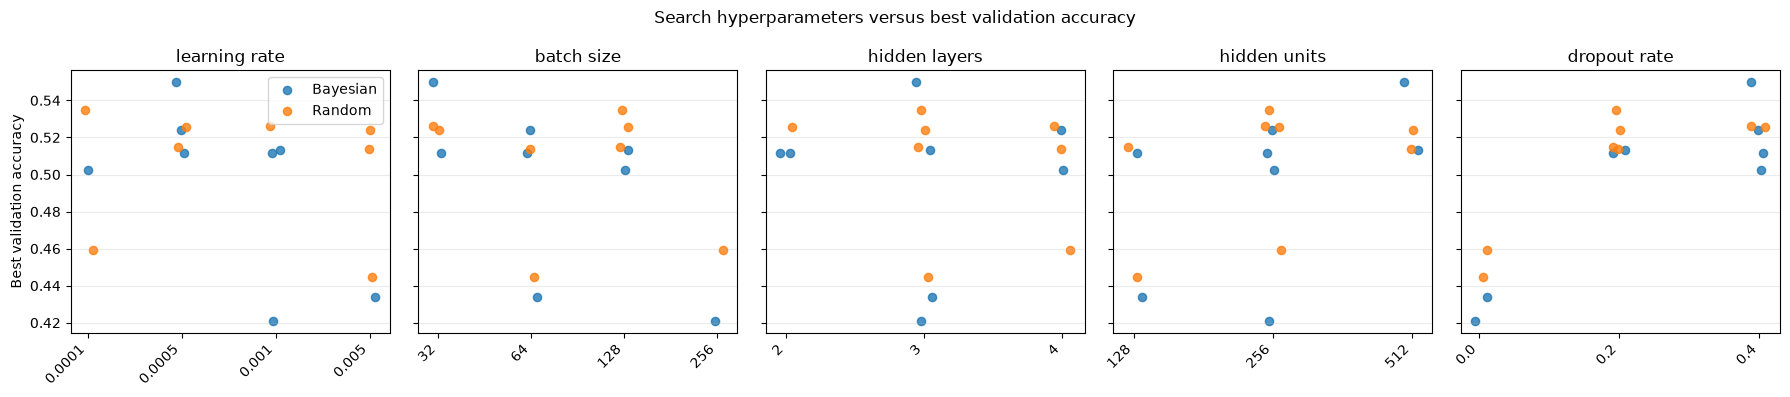

,method,best validation accuracy,mean ± std across trial-best validation scores,completed trials,total seconds
0,Random,0.5346,0.5054 ± 0.0339,8,788.0507
1,Bayesian,0.5498,0.4960 ± 0.0447,8,752.7257


**Search-method comparison.** With 8 random and 8 Bayesian trials completed, the best validation accuracies were 0.5346 and 0.5498, respectively; by this metric the result is **Bayesian optimization**. Observed cumulative trial times were 13.1 and 12.5 minutes on this CPU. The parameter plot is descriptive: only eight trials per method were sampled, so differences in per-value averages are noisy and do not establish general hyperparameter importance. Failed trials, if any, are identified by their recorded status in the tables.

In [8]:
bayesian_search = TimedBayesianOptimization(
    hypermodel=build_search_model, objective=kt.Objective("val_accuracy", direction="max"),
    max_trials=N_SEARCH_TRIALS, seed=SEED + 2, executions_per_trial=1,
    directory=tempfile.mkdtemp(prefix="aai640_bayesian_"), project_name="bayesian", overwrite=True,
)
bayesian_search.search(X_train, y_train, validation_data=(X_val, y_val),
                       epochs=MAX_EPOCHS, verbose=0)
bayesian_trials = tuner_trial_table(bayesian_search, "Bayesian")
bayesian_trials["key_observation"] = np.where(
    bayesian_trials["best_val_accuracy"] >= bayesian_trials["best_val_accuracy"].mean(),
    "at/above this search's mean", "below this search's mean"
)
display(bayesian_trials.sort_values("best_val_accuracy", ascending=False).round(4))
bayesian_best_model = bayesian_search.get_best_models(num_models=1)[0]
bayesian_best_hp = bayesian_search.get_best_hyperparameters(num_trials=1)[0].values
bayes_val_loss, bayes_val_accuracy = bayesian_best_model.evaluate(X_val, y_val, verbose=0)
print("Best Bayesian-search configuration:", bayesian_best_hp)
print("Validation loss/accuracy for the retained best-trial model:", round(float(bayes_val_loss), 4), round(float(bayes_val_accuracy), 4))

search_trials = pd.concat([random_trials, bayesian_trials], ignore_index=True)
search_trials_valid = search_trials.dropna(subset=["best_val_accuracy"]).copy()
fig, axes = plt.subplots(1, 5, figsize=(18, 4), sharey=True)
for ax, parameter in zip(axes, ["learning_rate", "batch_size", "hidden_layers", "hidden_units", "dropout_rate"]):
    categories = sorted(search_trials_valid[parameter].dropna().unique())
    positions = {value: index for index, value in enumerate(categories)}
    for method, group in search_trials_valid.groupby("method"):
        x = [positions[value] for value in group[parameter]]
        jitter = np.linspace(-0.06, 0.06, len(group)) if len(group) > 1 else [0]
        ax.scatter(np.array(x) + jitter, group["best_val_accuracy"], label=method if parameter == "learning_rate" else None,
                   alpha=.8, s=35)
    ax.set_xticks(range(len(categories)), [str(value) for value in categories], rotation=45, ha="right")
    ax.set_title(parameter.replace("_", " "))
    ax.grid(axis="y", alpha=.25)
axes[0].set_ylabel("Best validation accuracy")
axes[0].legend()
fig.suptitle("Search hyperparameters versus best validation accuracy")
plt.tight_layout()
plt.show()

random_best_score = float(random_trials["best_val_accuracy"].max())
bayes_best_score = float(bayesian_trials["best_val_accuracy"].max())
random_total_seconds = float(random_trials["training_seconds"].sum())
bayes_total_seconds = float(bayesian_trials["training_seconds"].sum())
search_winner = "Random search" if random_best_score > bayes_best_score else ("Bayesian optimization" if bayes_best_score > random_best_score else "Tie")
search_score_summary = pd.DataFrame([
    {"method": "Random", "best validation accuracy": random_best_score,
     "mean ± std across trial-best validation scores": f"{random_trials['best_val_accuracy'].mean():.4f} ± {random_trials['best_val_accuracy'].std(ddof=1):.4f}",
     "completed trials": int(random_trials["status"].eq("COMPLETED").sum()), "total seconds": random_total_seconds},
    {"method": "Bayesian", "best validation accuracy": bayes_best_score,
     "mean ± std across trial-best validation scores": f"{bayesian_trials['best_val_accuracy'].mean():.4f} ± {bayesian_trials['best_val_accuracy'].std(ddof=1):.4f}",
     "completed trials": int(bayesian_trials["status"].eq("COMPLETED").sum()), "total seconds": bayes_total_seconds},
])
display(search_score_summary.round(4))
display(Markdown(
    f"**Search-method comparison.** With {len(random_trials)} random and {len(bayesian_trials)} Bayesian trials completed, the best validation accuracies were "
    f"{random_best_score:.4f} and {bayes_best_score:.4f}, respectively; by this metric the result is **{search_winner}**. "
    f"Observed cumulative trial times were {random_total_seconds/60:.1f} and {bayes_total_seconds/60:.1f} minutes on this CPU. "
    f"The parameter plot is descriptive: only eight trials per method were sampled, so differences in per-value averages are noisy and do not establish general hyperparameter importance. "
    f"Failed trials, if any, are identified by their recorded status in the tables."
))

## 9. Step 7 — Select the final model and evaluate once on test

Compare validation results from the baseline, all three batch-size runs, BatchNormalization, and the best completed trial from each search method. Select using validation accuracy, with validation loss and measured fit time as deterministic tie-breaks. Retain the selected run’s weights from its best validation-accuracy epoch rather than retraining a different model. Only now, after selection is fixed, evaluate that one retained model on the held-out test set.

**Observed search findings.** All eight Bayesian trials completed. The best configuration used three hidden layers of 512 units, dropout 0.4, learning rate 0.0005, and batch size 32 (validation accuracy 0.5498). Its trial ID was 0; the first random-search trial (ID 0) also exceeded the baseline's best validation accuracy, so both methods met the explicit “at least baseline-level” threshold on their first trial. The two lowest-scoring Bayesian configurations also used zero dropout; given the small sample and multiple changing parameters, this is descriptive rather than causal evidence.

**Warning note.** KerasTuner emitted the same optimizer-slot restoration warning described after the random search. It concerns optimizer state only; the best model weights were restored, and the validation evaluation succeeded. No warning or failure was silently suppressed.

Across the sampled trials, the random-search best-validation-accuracy mean ± standard deviation was 0.5054 ± 0.0339; Bayesian optimization's was 0.4960 ± 0.0447. Thus, Bayesian optimization found the higher single best score, while its sampled scores were more variable and its mean was lower in this run. Using “match or exceed the baseline's best validation accuracy” as the operational threshold for a strong configuration, the first trial in each search met it (trial ID 0). This threshold is explicit and modest; it does not assert global optimality.

,configuration,best_validation_accuracy,best_validation_loss,validation_loss_at_best_accuracy,best_epoch,train_accuracy_at_best_epoch,configuration_details,training_seconds,training_epochs
6,Best Bayesian,0.5498,1.2798,1.2798,20,0.6071,"BatchNorm=True; {'hidden_layers': 3, 'hidden_u...",262.4711,30
5,Best random-search,0.5346,1.3131,1.3131,23,0.5963,"BatchNorm=True; {'hidden_layers': 3, 'hidden_u...",53.4150,30
3,Batch size 512,0.5228,1.3865,1.3865,22,0.5786,Baseline architecture; batch 512; no BatchNorm...,43.1562,30
2,Batch size 128,0.5070,1.4426,1.4426,18,0.5787,Baseline architecture; batch 128; no BatchNorm...,87.3126,30
0,Baseline,0.4876,1.4615,1.6103,29,0.6379,3 hidden layers 512/256/128; no BatchNorm/drop...,94.3852,30
1,Batch size 32,0.4754,1.4728,1.5045,11,0.5140,Baseline architecture; batch 32; no BatchNorm/...,212.7684,30
4,Batch-normalized,0.3952,1.7719,3.2933,22,0.9265,3 hidden layers 512/256/128; BatchNorm; batch ...,41.1025,30


Selected configuration: BatchNorm=True; {'hidden_layers': 3, 'hidden_units': 512, 'dropout_rate': 0.4, 'learning_rate': 0.0005, 'batch_size': 32}
Selected best validation accuracy / loss / epoch: 0.5498 1.2798 20
{'final_validation_accuracy': 0.5497999787330627, 'test_accuracy': 0.5419999957084656, 'test_loss': 1.2937119007110596, 'test_macro_f1': 0.5367173217174322}
              precision    recall  f1-score   support

    airplane     0.5393    0.6450    0.5874      1000
  automobile     0.6107    0.6840    0.6453      1000
        bird     0.4664    0.4030    0.4324      1000
         cat     0.3958    0.3360    0.3634      1000
        deer     0.5147    0.4540    0.4825      1000
         dog     0.5045    0.3950    0.4431      1000
        frog     0.5708    0.6050    0.5874      1000
       horse     0.5969    0.6160    0.6063      1000
        ship     0.6390    0.6690    0.6536      1000
       truck     0.5253    0.6130    0.5658      1000

    accuracy                      

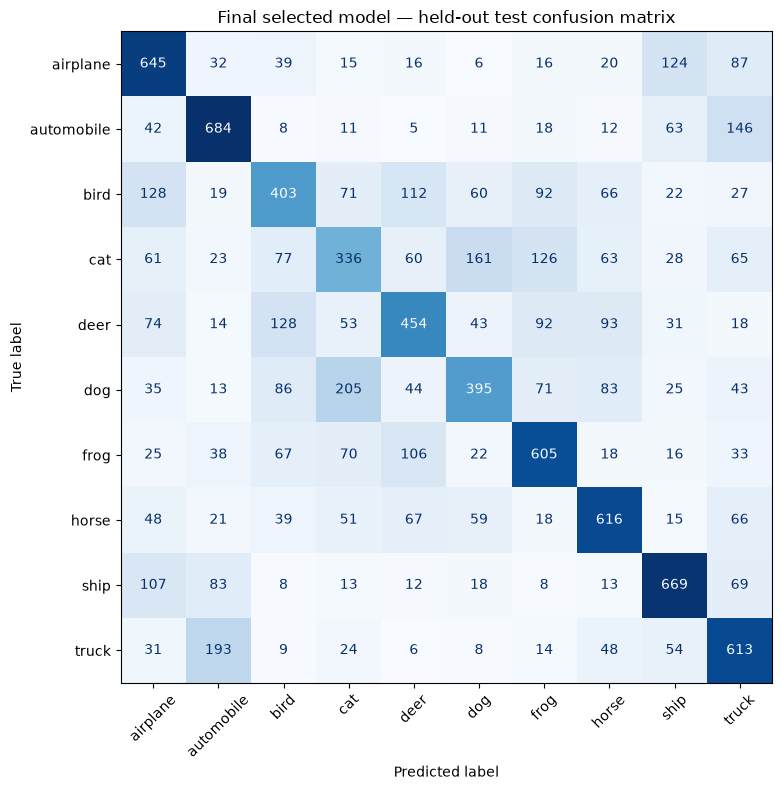

**Final evaluation.** The selected model was chosen using validation results and its best-validation-accuracy weights were retained; it was not retrained, so the reported validation and test results refer to the same weights. Its validation accuracy was 0.5498; held-out test accuracy was 0.5420, test loss 1.2937, and macro-F1 0.5367. The final model's validation-accuracy gain over the baseline was +0.0622. The test set was not used to tune any configuration.

In [9]:
candidate_rows = []
candidates = []

def add_candidate(name, model, metrics, configuration):
    row = {
        "configuration": name,
        "model": model,
        "best_validation_accuracy": float(metrics["best_val_accuracy"]),
        "best_validation_loss": float(metrics["best_val_loss"]),
        "validation_loss_at_best_accuracy": float(metrics["val_loss_at_best_epoch"]),
        "best_epoch": int(metrics["best_epoch"]),
        "train_accuracy_at_best_epoch": float(metrics["train_accuracy_at_best_epoch"]),
        "configuration_details": configuration,
        "training_seconds": float(metrics["training_seconds"]),
        "training_epochs": int(metrics["epochs_run"]),
    }
    candidates.append(row)

add_candidate("Baseline", baseline_model, baseline_result, "3 hidden layers 512/256/128; no BatchNorm/dropout; batch 128; default Adam")
for batch_size, result in batch_results.items():
    add_candidate(f"Batch size {batch_size}", batch_models[batch_size], result,
                  f"Baseline architecture; batch {batch_size}; no BatchNorm/dropout; default Adam")
add_candidate("Batch-normalized", bn_model, bn_result,
              f"3 hidden layers 512/256/128; BatchNorm; batch {best_batch_size}; default Adam")

# Search models are evaluated on validation only, after hyperparameter selection.
for method, model, hp, validation_loss, validation_accuracy, trials in [
    ("Best random-search", random_best_model, random_best_hp, random_val_loss, random_val_accuracy, random_trials),
    ("Best Bayesian", bayesian_best_model, bayesian_best_hp, bayes_val_loss, bayes_val_accuracy, bayesian_trials),
]:
    best_trial_row = trials.loc[trials["best_val_accuracy"].idxmax()]
    candidates.append({
        "configuration": method, "model": model,
        "best_validation_accuracy": float(validation_accuracy),
        "best_validation_loss": float(best_trial_row["best_val_loss"]),
        "validation_loss_at_best_accuracy": float(validation_loss),
        "best_epoch": int(best_trial_row["best_epoch"]),
        "train_accuracy_at_best_epoch": float(best_trial_row["train_accuracy_at_best_epoch"]),
        "configuration_details": "BatchNorm=True; " + str(hp),
        "training_seconds": float(best_trial_row["training_seconds"]),
        "training_epochs": int(best_trial_row["epochs_run"]),
    })

candidate_table = pd.DataFrame([{key: value for key, value in row.items() if key != "model"} for row in candidates])
display(candidate_table.sort_values(
    ["best_validation_accuracy", "validation_loss_at_best_accuracy", "training_seconds"],
    ascending=[False, True, True]
).round(4))

# Pick the first candidate after the stated validation-only ranking.
ranked_candidates = sorted(candidates, key=lambda row: (
    -row["best_validation_accuracy"], row["validation_loss_at_best_accuracy"], row["training_seconds"]
))
selected = ranked_candidates[0]
final_model = selected["model"]
print("Selected configuration:", selected["configuration_details"])
print("Selected best validation accuracy / loss / epoch:",
      round(selected["best_validation_accuracy"], 4), round(selected["validation_loss_at_best_accuracy"], 4), selected["best_epoch"])

# First and only test-set evaluation; predictions below support the same final evaluation's confusion matrix.
X_test = X_test_images.reshape(len(X_test_images), -1).astype(np.float32) / 255.0
test_loss, test_accuracy = final_model.evaluate(X_test, y_test, verbose=0)
test_probabilities = final_model.predict(X_test, batch_size=256, verbose=0)
test_predictions = np.argmax(test_probabilities, axis=1)
test_macro_f1 = f1_score(y_test, test_predictions, average="macro")
print({"final_validation_accuracy": selected["best_validation_accuracy"],
       "test_accuracy": float(test_accuracy), "test_loss": float(test_loss), "test_macro_f1": float(test_macro_f1)})
print(classification_report(y_test, test_predictions, target_names=CLASS_NAMES, digits=4, zero_division=0))

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_predictions), display_labels=CLASS_NAMES).plot(
    ax=ax, xticks_rotation=45, colorbar=False, cmap="Blues", values_format="d"
)
ax.set_title("Final selected model — held-out test confusion matrix")
plt.tight_layout()
plt.show()

baseline_validation_gain = selected["best_validation_accuracy"] - baseline_result["best_val_accuracy"]
display(Markdown(
    f"**Final evaluation.** The selected model was chosen using validation results and its best-validation-accuracy weights were retained; it was not retrained, so the reported validation and test results refer to the same weights. "
    f"Its validation accuracy was {selected['best_validation_accuracy']:.4f}; held-out test accuracy was {float(test_accuracy):.4f}, test loss {float(test_loss):.4f}, and macro-F1 {float(test_macro_f1):.4f}. "
    f"The final model's validation-accuracy gain over the baseline was {baseline_validation_gain:+.4f}. The test set was not used to tune any configuration."
))

## 10. Step 8 — Comparative analysis

The summary below applies one reporting rule throughout: training accuracy and best validation accuracy are reported at the epoch selected by validation accuracy; the separate best validation loss is also retained. The held-out test score appears only for the final selected model.

The trial-score mean ± standard deviation reported above summarizes variation among sampled configurations on the same fixed validation split; it is **not** a cross-validation estimate. Cross-validation would change the assignment-mandated 45,000/5,000 validation protocol and multiply the already substantial CPU training budget.

The `NaN` test entries for non-final configurations mean those models were deliberately not evaluated on the held-out test set. The trial-score mean ± standard deviation is across sampled configurations on one validation set, not cross-validation.

In [10]:
summary_rows = []
def summary_row(name, result, observation, test_score=None):
    summary_rows.append({
        "configuration": name,
        "training accuracy at best-validation-accuracy epoch": result["train_accuracy_at_best_epoch"],
        "best validation accuracy": result["best_val_accuracy"],
        "best validation loss": result["best_val_loss"],
        "best epoch": result["best_epoch"],
        "training epochs run": result["epochs_run"],
        "test accuracy (final only)": test_score,
        "key observation": observation,
    })

summary_row("Baseline", baseline_result, "Fixed 512/256/128 ReLU model; no BatchNorm or dropout")
best_batch_result = batch_results[best_batch_size]
summary_row(f"Best batch size ({best_batch_size})", best_batch_result,
            f"Selected from 32/128/512 by validation ranking; {best_batch_result['updates_per_epoch']} updates/epoch")
summary_row("Batch-normalized model", bn_result, f"Dense → BatchNorm → ReLU; batch {best_batch_size}")
random_row = random_trials.loc[random_trials["best_val_accuracy"].idxmax()]
bayes_row = bayesian_trials.loc[bayesian_trials["best_val_accuracy"].idxmax()]
summary_row("Best random-search model", {
    "train_accuracy_at_best_epoch": float(random_row["train_accuracy_at_best_epoch"]), "best_val_accuracy": random_val_accuracy,
    "best_val_loss": random_val_loss, "best_epoch": int(random_row["best_epoch"]), "epochs_run": int(random_row["epochs_run"])
}, f"{int(random_trials['status'].eq('COMPLETED').sum())} completed trials; configuration {random_best_hp}")
summary_row("Best Bayesian model", {
    "train_accuracy_at_best_epoch": float(bayes_row["train_accuracy_at_best_epoch"]), "best_val_accuracy": bayes_val_accuracy,
    "best_val_loss": bayes_val_loss, "best_epoch": int(bayes_row["best_epoch"]), "epochs_run": int(bayes_row["epochs_run"])
}, f"{int(bayesian_trials['status'].eq('COMPLETED').sum())} completed trials; configuration {bayesian_best_hp}")
summary_row("Final selected model", {
    "train_accuracy_at_best_epoch": selected["train_accuracy_at_best_epoch"],
    "best_val_accuracy": selected["best_validation_accuracy"],
    "best_val_loss": selected["best_validation_loss"], "best_epoch": selected["best_epoch"], "epochs_run": selected["training_epochs"]
}, f"Retained best validation checkpoint: {selected['configuration_details']}", float(test_accuracy))
summary_table = pd.DataFrame(summary_rows)
display(summary_table.round(4))

best_batch_change = batch_results[best_batch_size]["best_val_accuracy"] - baseline_result["best_val_accuracy"]
random_bayes_difference = random_best_score - bayes_best_score
interpretation = (
    f"The selected final configuration was **{selected['configuration']}** ({selected['configuration_details']}). "
    f"Relative to the fixed baseline, its validation accuracy changed by {baseline_validation_gain:+.4f}; the best batch-size experiment changed validation accuracy by {best_batch_change:+.4f} versus the baseline. "
    f"BatchNormalization changed validation accuracy by {delta_bn:+.4f} relative to the matched no-BatchNorm run. "
    f"Random-search best validation accuracy minus Bayesian best validation accuracy was {random_bayes_difference:+.4f}. "
    f"These differences are specific to the sampled configurations and fixed seed. Selection on validation data can itself overfit the validation set, particularly after many trials; the single held-out test evaluation provides the final generalization check."
)
display(Markdown("**Comparative findings.** " + interpretation))

,configuration,training accuracy at best-validation-accuracy epoch,best validation accuracy,best validation loss,best epoch,training epochs run,test accuracy (final only),key observation
0,Baseline,0.6379,0.4876,1.4615,29,30,NaN,Fixed 512/256/128 ReLU model; no BatchNorm or ...
1,Best batch size (512),0.5786,0.5228,1.3865,22,30,NaN,Selected from 32/128/512 by validation ranking...
2,Batch-normalized model,0.9265,0.3952,1.7719,22,30,NaN,Dense → BatchNorm → ReLU; batch 512
3,Best random-search model,0.5963,0.5346,1.3131,23,30,NaN,8 completed trials; configuration {'hidden_lay...
4,Best Bayesian model,0.6071,0.5498,1.2798,20,30,NaN,8 completed trials; configuration {'hidden_lay...
5,Final selected model,0.6071,0.5498,1.2798,20,30,0.542,Retained best validation checkpoint: BatchNorm...


**Comparative findings.** The selected final configuration was **Best Bayesian** (BatchNorm=True; {'hidden_layers': 3, 'hidden_units': 512, 'dropout_rate': 0.4, 'learning_rate': 0.0005, 'batch_size': 32}). Relative to the fixed baseline, its validation accuracy changed by +0.0622; the best batch-size experiment changed validation accuracy by +0.0352 versus the baseline. BatchNormalization changed validation accuracy by -0.1276 relative to the matched no-BatchNorm run. Random-search best validation accuracy minus Bayesian best validation accuracy was -0.0152. These differences are specific to the sampled configurations and fixed seed. Selection on validation data can itself overfit the validation set, particularly after many trials; the single held-out test evaluation provides the final generalization check.

## 11. Step 9 — Final analysis and reflection

Answer the assignment questions using the observed comparisons. The generated response below reports measured differences and frames them as results of these controlled runs, not universal claims.

In [11]:
reflection = (
    f"Across this workflow, batch size {best_batch_size} produced the strongest validation result among the three tested values; its validation accuracy was {best_batch_result['best_val_accuracy']:.4f}, "
    f"with {best_batch_result['updates_per_epoch']} updates per epoch and {best_batch_result['training_seconds']:.1f} seconds of observed fit time. "
    f"The BatchNorm model's validation-accuracy change relative to the matched no-BatchNorm model was {delta_bn:+.4f}; its curves and best epoch ({bn_result['best_epoch']}) show how optimization behavior differed in this run. "
    f"Among eight-trial searches, random search reached {random_best_score:.4f} validation accuracy and Bayesian optimization reached {bayes_best_score:.4f}; neither method is assumed to dominate with this limited budget. "
    f"The final model was selected by validation accuracy, with validation loss and runtime used only as tie-breaks, and the retained best-validation checkpoint was evaluated once on test data. "
    f"Its validation accuracy was {selected['best_validation_accuracy']:.4f} and test accuracy was {float(test_accuracy):.4f}. The difference is a useful generalization diagnostic, but one split and one seed do not quantify uncertainty across repeated samples."
)
display(Markdown(reflection))

Across this workflow, batch size 512 produced the strongest validation result among the three tested values; its validation accuracy was 0.5228, with 88 updates per epoch and 43.2 seconds of observed fit time. The BatchNorm model's validation-accuracy change relative to the matched no-BatchNorm model was -0.1276; its curves and best epoch (22) show how optimization behavior differed in this run. Among eight-trial searches, random search reached 0.5346 validation accuracy and Bayesian optimization reached 0.5498; neither method is assumed to dominate with this limited budget. The final model was selected by validation accuracy, with validation loss and runtime used only as tie-breaks, and the retained best-validation checkpoint was evaluated once on test data. Its validation accuracy was 0.5498 and test accuracy was 0.5420. The difference is a useful generalization diagnostic, but one split and one seed do not quantify uncertainty across repeated samples.

**Final-model justification.** The selected Bayesian configuration had the best validation accuracy among the compared candidates (0.5498), and its one-time test accuracy was 0.5420 (a validation-to-test difference of −0.0078). This supports the validation-based choice on this held-out partition, while the single seed and single test evaluation limit claims about broader robustness.